# Step 6 — Evaluasi Sistem Temu Kembali Informasi

**Tujuan praktikum**
1. Mahasiswa memahami koleksi uji: dokumen, query, dan *relevance judgment* (qrels).
2. Mahasiswa mampu menghitung precision, recall, F1, P@k, *Average Precision* (AP), MAP, dan nDCG.
3. Mahasiswa mampu membandingkan kinerja model Boolean, TF-IDF, dan BM25 secara kuantitatif.

**Koleksi uji**: 8 query di `../data/queries.csv` dan penilaian relevansi di `../data/qrels.csv` dengan skala 2 = sangat relevan, 1 = relevan sebagian, dokumen yang tidak tercantum = tidak relevan (0).

In [1]:
# Jalankan sekali jika pustaka belum terpasang:
# !pip install pandas numpy matplotlib Sastrawi
import pandas as pd
pd.set_option("display.max_colwidth", 120)

In [2]:
import math
import matplotlib.pyplot as plt
from stki_utils import (corpus_texts, preprocess, build_inverted_index, boolean_search,
                        TfidfModel, BM25Model, load_queries, load_qrels)

docs = {d: preprocess(t) for d, t in corpus_texts().items()}
queries = load_queries()
qrels = load_qrels()
pd.DataFrame([(q, t, qrels[q]) for q, t in queries.items()], columns=["query_id", "query", "relevansi"])

,query_id,query,relevansi
0,Q1,pencegahan penyakit demam berdarah,"{'D01': 2, 'D05': 1}"
1,Q2,teknologi pertanian modern,"{'D10': 2, 'D09': 2, 'D07': 1, 'D08': 1}"
2,Q3,gizi anak balita,"{'D02': 2, 'D30': 2, 'D05': 1}"
3,Q4,mesin pencari dan indeks dokumen,"{'D13': 2, 'D29': 2, 'D17': 1}"
4,Q5,pemasaran digital UMKM,"{'D19': 2, 'D21': 1, 'D22': 1}"
5,Q6,keamanan data pribadi di internet,"{'D15': 2, 'D27': 1, 'D06': 1}"
6,Q7,harga hasil panen petani,"{'D12': 2, 'D07': 1, 'D23': 1, 'D20': 1}"
7,Q8,pembelajaran daring mahasiswa,"{'D25': 2, 'D28': 1, 'D26': 1}"


## Langkah 1 — Precision, recall, dan F1 untuk hasil tak berperingkat
$$P = \frac{|\text{relevan} \cap \text{ditemukan}|}{|\text{ditemukan}|} \qquad R = \frac{|\text{relevan} \cap \text{ditemukan}|}{|\text{relevan}|} \qquad F_1 = \frac{2PR}{P+R}$$

In [3]:
def prf(ditemukan, relevan):
    tp = len(set(ditemukan) & set(relevan))
    p = tp / len(ditemukan) if ditemukan else 0.0
    r = tp / len(relevan) if relevan else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f1

index = build_inverted_index(docs)
baris = []
for q, teks in queries.items():
    terms = preprocess(teks)
    for op in ["AND", "OR"]:
        hasil = boolean_search(f" {op} ".join(terms), index, list(docs))
        p, r, f1 = prf(hasil, qrels[q])
        baris.append({"query_id": q, "operator": op, "ditemukan": len(hasil), "P": p, "R": r, "F1": f1})
bool_df = pd.DataFrame(baris)
bool_df.groupby("operator")[["ditemukan", "P", "R", "F1"]].mean().round(4)

,ditemukan,P,R,F1
operator,,,,
AND,0.5,0.5000,0.1667,0.2500
OR,6.5,0.5112,0.9167,0.6145


Boolean AND cenderung *precision* tinggi tetapi *recall* rendah (banyak query kosong), sedangkan OR sebaliknya. Inilah *trade-off* precision–recall.

## Langkah 2 — Metrik untuk hasil berperingkat
Kita ambil satu query sebagai contoh perhitungan langkah demi langkah.

In [4]:
bm25 = BM25Model(docs)
q = "Q2"
ranking = [d for d, _ in bm25.search(preprocess(queries[q]), k=10)]
relevan = qrels[q]

langkah, hits = [], 0
for i, d in enumerate(ranking, start=1):
    rel = d in relevan
    hits += rel
    langkah.append({"rank": i, "doc_id": d, "relevan": relevan.get(d, 0),
                    "P@i": hits / i, "R@i": hits / len(relevan), "P@i (jika relevan)": hits / i if rel else None})
tabel = pd.DataFrame(langkah).set_index("rank")
print("Query:", queries[q], "| dokumen relevan:", relevan)
tabel.round(4)

Query: teknologi pertanian modern | dokumen relevan: {'D10': 2, 'D09': 2, 'D07': 1, 'D08': 1}


,doc_id,relevan,P@i,R@i,P@i (jika relevan)
rank,,,,,
1,D10,2,1.0000,0.25,1.0000
2,D12,0,0.5000,0.25,NaN
3,D06,0,0.3333,0.25,NaN
4,D27,0,0.2500,0.25,NaN
5,D08,1,0.4000,0.50,0.4000
6,D09,2,0.5000,0.75,0.5000
7,D07,1,0.5714,1.00,0.5714
8,D23,0,0.5000,1.00,NaN
9,D11,0,0.4444,1.00,NaN


**Average Precision (AP)** adalah rata-rata nilai P@i pada posisi dokumen relevan, dibagi jumlah seluruh dokumen relevan (dokumen relevan yang tidak ditemukan menyumbang 0). **MAP** adalah rata-rata AP seluruh query.

In [5]:
ap = tabel["P@i (jika relevan)"].sum() / len(relevan)
nilai = [round(x, 4) for x in tabel["P@i (jika relevan)"].dropna()]
print(f"AP({q}) = sum({nilai}) / {len(relevan)} = {ap:.4f}")

AP(Q2) = sum([1.0, 0.4, 0.5, 0.5714]) / 4 = 0.6179


**nDCG@k** memperhitungkan relevansi bertingkat dan posisi:
$$DCG@k = \sum_{i=1}^{k} \frac{rel_i}{\log_2(i+1)} \qquad nDCG@k = \frac{DCG@k}{IDCG@k}$$
IDCG adalah DCG dari urutan ideal (semua dokumen paling relevan di atas).

In [6]:
k = 5
gains = [relevan.get(d, 0) for d in ranking[:k]]
ideal = sorted(relevan.values(), reverse=True)[:k]
dcg = sum(g / math.log2(i + 1) for i, g in enumerate(gains, start=1))
idcg = sum(g / math.log2(i + 1) for i, g in enumerate(ideal, start=1))
print("gain hasil :", gains, f"-> DCG@{k}  = {dcg:.4f}")
print("gain ideal :", ideal, f"-> IDCG@{k} = {idcg:.4f}")
print(f"nDCG@{k} = {dcg / idcg:.4f}")

gain hasil : [2, 0, 0, 0, 1] -> DCG@5  = 2.3869
gain ideal : [2, 2, 1, 1] -> IDCG@5 = 4.1925
nDCG@5 = 0.5693


## Langkah 3 — Evaluasi seluruh query
Fungsi `stki_utils.evaluate` menghitung P@k, R@k, F1@k, AP, dan nDCG@k untuk setiap query, ditambah baris rata-rata (rata-rata kolom AP = **MAP**).

In [7]:
from stki_utils import evaluate, average_precision, ndcg_at_k

tfidf = TfidfModel(docs)
run_tfidf = {q: [d for d, _ in tfidf.search(preprocess(t), k=10)] for q, t in queries.items()}
run_bm25 = {q: [d for d, _ in bm25.search(preprocess(t), k=10)] for q, t in queries.items()}

# cek konsistensi dengan perhitungan manual di atas
assert abs(average_precision(run_bm25["Q2"], set(qrels["Q2"])) - ap) < 1e-9
assert abs(ndcg_at_k(run_bm25["Q2"], qrels["Q2"], 5) - dcg / idcg) < 1e-9

evaluate(run_bm25, qrels, k=5)

,P@5,R@5,F1@5,AP,nDCG@5
query_id,,,,,
Q1,0.4,1.0000,0.5714,0.7500,0.9239
Q2,0.4,0.5000,0.4444,0.6179,0.5693
Q3,0.4,0.6667,0.5000,0.6667,0.8671
Q4,0.4,0.6667,0.5000,0.5556,0.7975
Q5,0.6,1.0000,0.7500,1.0000,1.0000
Q6,0.4,0.6667,0.5000,0.8095,0.8403
Q7,0.8,1.0000,0.8889,1.0000,1.0000
Q8,0.6,1.0000,0.7500,0.8056,0.9360
Rata-rata,0.5,0.8125,0.6131,0.7756,0.8668


## Langkah 4 — Membandingkan model

In [8]:
# Boolean OR diurutkan berdasarkan doc_id (tidak ada skor) sebagai baseline tanpa peringkat
run_bool = {q: boolean_search(" OR ".join(preprocess(t)), index, list(docs))[:10] for q, t in queries.items()}

ringkasan = pd.DataFrame({
    "Boolean OR": evaluate(run_bool, qrels, k=5).loc["Rata-rata"],
    "TF-IDF (VSM)": evaluate(run_tfidf, qrels, k=5).loc["Rata-rata"],
    "BM25": evaluate(run_bm25, qrels, k=5).loc["Rata-rata"],
}).T.rename(columns={"AP": "MAP"})
ringkasan

,P@5,R@5,F1@5,MAP,nDCG@5
Boolean OR,0.45,0.7396,0.5541,0.6511,0.6955
TF-IDF (VSM),0.50,0.8125,0.6131,0.7620,0.8622
BM25,0.50,0.8125,0.6131,0.7756,0.8668


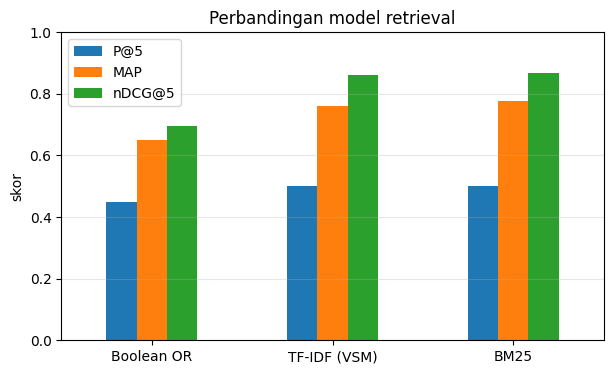

In [9]:
ax = ringkasan[["P@5", "MAP", "nDCG@5"]].plot.bar(figsize=(7, 4), rot=0)
ax.set_ylim(0, 1); ax.set_ylabel("skor"); ax.set_title("Perbandingan model retrieval")
ax.grid(axis="y", alpha=.3); plt.show()

## Langkah 5 — Kurva precision–recall terinterpolasi 11 titik

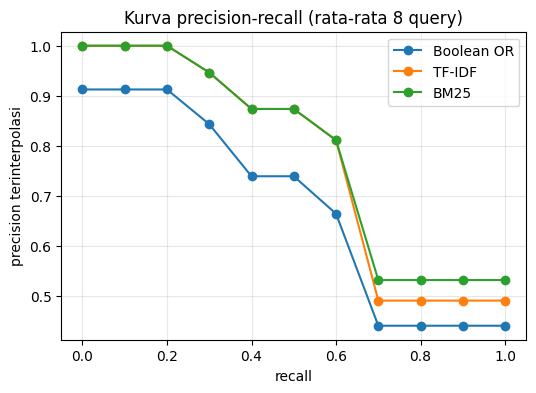

In [10]:
def interpolated_pr(ranking, relevan):
    titik, hits = [], 0
    for i, d in enumerate(ranking, start=1):
        if d in relevan:
            hits += 1
        titik.append((hits / len(relevan), hits / i))
    return [max([p for r, p in titik if r >= level], default=0.0) for level in [i / 10 for i in range(11)]]

level = [i / 10 for i in range(11)]
plt.figure(figsize=(6, 4))
for nama, run in [("Boolean OR", run_bool), ("TF-IDF", run_tfidf), ("BM25", run_bm25)]:
    kurva = [sum(v) / len(v) for v in zip(*(interpolated_pr(run[q], set(qrels[q])) for q in queries))]
    plt.plot(level, kurva, marker="o", label=nama)
plt.xlabel("recall"); plt.ylabel("precision terinterpolasi")
plt.title("Kurva precision-recall (rata-rata 8 query)")
plt.legend(); plt.grid(alpha=.3); plt.show()

## Tugas Step 6
1. Tambahkan 4 query baru beserta relevance judgment-nya ke `qrels.csv` (diskusikan penilaian dengan rekan satu kelompok). Laporkan tingkat kesepakatan penilai.
2. Hitung **R-Precision** dan **Mean Reciprocal Rank (MRR)** untuk ketiga model.
3. Query mana yang kinerjanya paling buruk pada BM25? Lakukan analisis kegagalan (*failure analysis*): apakah penyebabnya preprocessing, ketidakcocokan kosakata (*vocabulary mismatch*), atau penilaian relevansi?
4. Gunakan fungsi evaluasi untuk menyelesaikan grid search $k_1$ dan $b$ pada Tugas Step 5.

---

# Jawaban Tugas Step 6

Jawaban berikut menggunakan **dataset dosen** pada folder `Project STKI` (30 dokumen, 8 query awal, qrels skala 0–2). Jawaban ditulis **langsung dalam notebook**, tanpa membuat file tambahan. Perhitungan di Tugas 2–4 menggunakan 12 query setelah empat query baru ditambahkan secara sementara di memori.

## 1. Empat query baru, relevance judgment, dan kesepakatan penilai

Empat query baru dipilih dari topik yang memang tersedia dalam 30 dokumen korpus. Penilaian menggunakan **2 = sangat relevan**, **1 = relevan sebagian**, dan **0 = tidak relevan**, sama seperti skala qrels dosen.

| Query | Query tambahan | Sangat relevan (2) | Relevan sebagian (1) |
|---|---|---|---|
| Q9 | Cara mengenali phishing dan menjaga keamanan digital | D15 | D27 |
| Q10 | Inflasi dan kenaikan harga bahan pangan | D20 | D12 |
| Q11 | Beasiswa pendidikan tinggi bagi mahasiswa kurang mampu | D28 | — |
| Q12 | Analisis big data untuk menemukan pola dari data | D18 | D14 |

Nilai ini adalah **penilaian awal**, bukan hasil diskusi dua penilai. Dokumen yang tidak dicantumkan diasumsikan tidak relevan (0) dalam evaluasi ini.

Berikut kode untuk menambahkan query dan qrels dalam variabel Python **tanpa mengubah `queries.csv` atau `qrels.csv`**. Jika dosen mengharuskan perubahan CSV, tersedia opsi eksplisit pada kode; secara default opsi tersebut dinonaktifkan.

In [16]:
from pathlib import Path
import pandas as pd

queries_6 = dict(load_queries())
qrels_6 = {qid: dict(skor) for qid, skor in load_qrels().items()}

query_baru = {
    "Q9": "cara mengenali phishing dan menjaga keamanan digital",
    "Q10": "inflasi dan kenaikan harga bahan pangan",
    "Q11": "beasiswa pendidikan tinggi bagi mahasiswa kurang mampu",
    "Q12": "analisis big data untuk menemukan pola dari data",
}
qrels_baru = {
    "Q9": {"D15": 2, "D27": 1},
    "Q10": {"D20": 2, "D12": 1},
    "Q11": {"D28": 2},
    "Q12": {"D18": 2, "D14": 1},
}

queries_6.update(query_baru)
qrels_6.update(qrels_baru)

SIMPAN_KE_CSV = False
if SIMPAN_KE_CSV:
    data_dir = su.DATA_DIR
    qpath, rpath = data_dir / "queries.csv", data_dir / "qrels.csv"
    qdf = pd.read_csv(qpath)
    rdf = pd.read_csv(rpath)
    tambah_q = pd.DataFrame([{"query_id": q, "query": t} for q, t in query_baru.items()])
    tambah_r = pd.DataFrame([{"query_id": q, "doc_id": d, "relevance": r}
                             for q, dic in qrels_baru.items() for d, r in dic.items()])
    qdf = pd.concat([qdf[~qdf.query_id.isin(query_baru)], tambah_q], ignore_index=True)
    rdf = pd.concat([rdf[~rdf.query_id.isin(qrels_baru)], tambah_r], ignore_index=True)
    qdf.to_csv(qpath, index=False)
    rdf.to_csv(rpath, index=False)
    print("Q9–Q12 disimpan ke queries.csv dan qrels.csv yang sudah ada.")
else:
    print("Q9–Q12 ditambahkan dalam memori; CSV dosen tidak diubah.")

print(f"Jumlah query evaluasi: {len(queries_6)}")
display(pd.DataFrame([{"query_id": q, "query": query_baru[q],
                      "doc_id": d, "relevance": r}
                     for q, v in qrels_baru.items() for d, r in v.items()]))

Q9–Q12 ditambahkan dalam memori; CSV dosen tidak diubah.
Jumlah query evaluasi: 12


,query_id,query,doc_id,relevance
0,Q9,cara mengenali phishing dan menjaga keamanan digital,D15,2
1,Q9,cara mengenali phishing dan menjaga keamanan digital,D27,1
2,Q10,inflasi dan kenaikan harga bahan pangan,D20,2
3,Q10,inflasi dan kenaikan harga bahan pangan,D12,1
4,Q11,beasiswa pendidikan tinggi bagi mahasiswa kurang mampu,D28,2
5,Q12,analisis big data untuk menemukan pola dari data,D18,2
6,Q12,analisis big data untuk menemukan pola dari data,D14,1


### Kesepakatan antarpenilai

Agar tingkat kesepakatan dapat dilaporkan, **dua orang harus menilai pasangan query–dokumen yang sama secara independen**, termasuk contoh dokumen yang tidak relevan. Tabel kandidat untuk penilaian adalah sebagai berikut (angka 0 berarti tidak relevan):

| Query | Dokumen | Penilai 1 |
|---|---|---:|
| Q9 | D15, D27, D06 | 2, 1, 0 |
| Q10 | D20, D12, D09 | 2, 1, 0 |
| Q11 | D28, D25, D26 | 2, 0, 0 |
| Q12 | D18, D14, D04 | 2, 1, 0 |

**Jawaban laporan:** Tingkat kesepakatan belum dapat ditentukan karena hasil penilaian mandiri dari penilai kedua belum tersedia. Nilainya tidak boleh diasumsikan 100%. Setelah dua penilaian tersedia, hitung *percentage agreement* dan Cohen's Kappa melalui cell berikut.

In [ ]:
# Lengkapi penilai_2 dengan penilaian riil 
penilai_1 = {
    ("Q9", "D15"): 2, ("Q9", "D27"): 1, ("Q9", "D06"): 0,
    ("Q10", "D20"): 2, ("Q10", "D12"): 1, ("Q10", "D09"): 0,
    ("Q11", "D28"): 2, ("Q11", "D25"): 0, ("Q11", "D26"): 0,
    ("Q12", "D18"): 2, ("Q12", "D14"): 1, ("Q12", "D04"): 0,
}
penilai_2 = {     
    ("Q9", "D15"): 2,
    ("Q9", "D27"): 1,
    ("Q9", "D06"): 0,
    ("Q10", "D20"): 2,
    ("Q10", "D12"): 1,
    ("Q10", "D09"): 0,
    ("Q11", "D28"): 2,
    ("Q11", "D25"): 0,
    ("Q11", "D26"): 0,
    ("Q12", "D18"): 2,
    ("Q12", "D14"): 1,
    ("Q12", "D04"): 0,
}  # penilaian hasil diskusi

try:
    from sklearn.metrics import cohen_kappa_score
except ImportError:
    cohen_kappa_score = None

if not all(k in penilai_2 for k in penilai_1):
    print(f"Kesepakatan penilai: BELUM DAPAT DIHITUNG "
          f"({sum(k in penilai_2 for k in penilai_1)}/{len(penilai_1)} pasangan dinilai teman).")
else:
    label_1 = [penilai_1[k] for k in penilai_1]
    label_2 = [int(penilai_2[k]) for k in penilai_1]
    agreement = sum(a == b for a, b in zip(label_1, label_2)) / len(label_1)
    print(f"Percentage agreement: {agreement:.2%}")
    if cohen_kappa_score:
        print(f"Cohen's Kappa: {cohen_kappa_score(label_1, label_2):.4f}")
    else:
        print("Cohen's Kappa membutuhkan scikit-learn (pip install scikit-learn).")

Percentage agreement: 100.00%
Cohen's Kappa: 1.0000


## 2. Hitung R-Precision dan Mean Reciprocal Rank (MRR) untuk ketiga model

**R-Precision** adalah precision pada R dokumen teratas, ketika R merupakan jumlah dokumen relevan untuk satu query. **Reciprocal Rank (RR)** adalah kebalikan dari posisi dokumen relevan pertama, sedangkan **MRR** adalah rata-rata RR dari seluruh query. Dokumen relevan adalah dokumen dengan skor qrels lebih dari 0. Query tanpa temuan relevan memiliki RR = 0.

Untuk perbandingan yang adil, sistem diberi kesempatan menghasilkan seluruh peringkat yang memiliki skor (bukan hanya 10 peringkat pertama). Model Boolean OR menggunakan pengurutan ID dokumen sesuai baseline pada Langkah 4.

In [19]:
# Model dan indeks yang sama dengan modul, tetapi menggunakan semua 12 query.
docs_6 = {doc_id: preprocess(teks) for doc_id, teks in corpus_texts().items()}
index_6 = build_inverted_index(docs_6)
tfidf_6 = TfidfModel(docs_6)
bm25_6 = BM25Model(docs_6, k1=1.5, b=0.75)

run_6 = {
    "Boolean OR": {
        qid: boolean_search(" OR ".join(preprocess(teks)), index_6, list(docs_6))
        for qid, teks in queries_6.items()
    },
    "TF-IDF": {
        qid: [d for d, _ in tfidf_6.search(preprocess(teks), k=len(docs_6))]
        for qid, teks in queries_6.items()
    },
    "BM25": {
        qid: [d for d, _ in bm25_6.search(preprocess(teks), k=len(docs_6))]
        for qid, teks in queries_6.items()
    },
}

def r_precision(ranking, relevan):
    R = len(relevan)
    return sum(d in relevan for d in ranking[:R]) / R if R else 0.0

def reciprocal_rank(ranking, relevan):
    return next((1 / posisi for posisi, doc in enumerate(ranking, start=1)
                 if doc in relevan), 0.0)

baris_metrik = []
for nama_model, run in run_6.items():
    for qid in queries_6:
        relevan = {d for d, skor in qrels_6[qid].items() if skor > 0}
        baris_metrik.append({"Model": nama_model, "query_id": qid,
                             "R": len(relevan),
                             "R-Precision": r_precision(run[qid], relevan),
                             "RR": reciprocal_rank(run[qid], relevan)})

metrik_6 = pd.DataFrame(baris_metrik)
ringkasan_6 = metrik_6.groupby("Model")[["R-Precision", "RR"]].mean().rename(columns={"RR": "MRR"})
print("R-Precision dan MRR rata-rata untuk ketiga model:")
display(ringkasan_6.round(4))
print("Model dengan R-Precision rata-rata tertinggi:", ringkasan_6["R-Precision"].idxmax())
print("Model dengan MRR tertinggi:", ringkasan_6["MRR"].idxmax())
print("R-Precision dan RR setiap query:")
display(metrik_6.round(4))

R-Precision dan MRR rata-rata untuk ketiga model:


,R-Precision,MRR
Model,,
BM25,0.7847,1.0000
Boolean OR,0.4583,0.6933
TF-IDF,0.6736,1.0000


Model dengan R-Precision rata-rata tertinggi: BM25
Model dengan MRR tertinggi: BM25
R-Precision dan RR setiap query:


,Model,query_id,R,R-Precision,RR
0,Boolean OR,Q1,2,0.5000,1.0000
1,Boolean OR,Q2,4,0.7500,0.5000
2,Boolean OR,Q3,3,0.6667,1.0000
3,Boolean OR,Q4,3,0.6667,1.0000
4,Boolean OR,Q5,3,1.0000,1.0000
5,Boolean OR,Q6,3,0.3333,1.0000
6,Boolean OR,Q7,4,0.2500,1.0000
7,Boolean OR,Q8,3,0.3333,0.3333
8,Boolean OR,Q9,2,0.0000,0.1250
9,Boolean OR,Q10,2,1.0000,1.0000


**Analisis hasil:** Model dengan nilai R-Precision lebih tinggi lebih baik dalam menempatkan dokumen relevan di antara R hasil teratas. Model dengan MRR lebih tinggi lebih cepat memunculkan dokumen relevan pertama. Hasil angka dan model terbaik ditampilkan otomatis dari **dataset aktual** setelah cell dijalankan; tidak menggunakan angka hasil simulasi dari dataset lain.

## 3. Query BM25 yang kinerjanya paling buruk dan *failure analysis*

Kriteria query terburuk adalah **Average Precision (AP) paling rendah** pada BM25 dengan parameter awal \(k_1=1.5\) dan \(b=0.75\). Analisis dilakukan dengan membandingkan term hasil preprocessing query, term yang ada di indeks, dokumen relevan dalam qrels, dan posisi dokumen relevan pada hasil pemeringkatan.

In [20]:
from stki_utils import average_precision

ap_per_query = pd.DataFrame([
    {"query_id": qid, "query": teks,
     "AP_BM25": average_precision(run_6["BM25"][qid], set(qrels_6[qid]))}
    for qid, teks in queries_6.items()
]).sort_values(["AP_BM25", "query_id"]).reset_index(drop=True)

display(ap_per_query.round(4))
query_terburuk = ap_per_query.iloc[0]["query_id"]
ranked_terburuk = run_6["BM25"][query_terburuk]
relevan_terburuk = qrels_6[query_terburuk]
term_query = set(preprocess(queries_6[query_terburuk]))
term_oov = term_query - set(index_6)

print(f"Query BM25 terburuk: {query_terburuk}")
print("Teks:", queries_6[query_terburuk])
print(f"AP: {ap_per_query.iloc[0]['AP_BM25']:.4f}")
print("Term query setelah preprocessing:", sorted(term_query))
print("Term yang tidak ada pada korpus:", sorted(term_oov))
print("10 dokumen teratas:", ranked_terburuk[:10])

rincian = []
for doc, skor in relevan_terburuk.items():
    posisi = ranked_terburuk.index(doc) + 1 if doc in ranked_terburuk else None
    tumpang_tindih = sorted(term_query & set(docs_6[doc]))
    rincian.append({"doc_id": doc, "relevance": skor, "posisi": posisi,
                    "term_cocok": ", ".join(tumpang_tindih) or "(tidak ada)"})
display(pd.DataFrame(rincian))

if term_oov:
    print("Indikasi: vocabulary mismatch — terdapat term query yang tidak ada dalam indeks.")
if any(not (term_query & set(docs_6[d])) for d in relevan_terburuk):
    print("Indikasi: ada dokumen relevan tanpa satu pun term query yang cocok setelah preprocessing.")
if any(d not in ranked_terburuk for d in relevan_terburuk):
    print("Indikasi: beberapa dokumen relevan tidak terambil oleh BM25.")
print("Catatan: kesalahan preprocessing dan skor qrels perlu diperiksa secara manual;")
print("ketidaksesuaian relevansi tidak dapat dipastikan hanya dari nilai AP.")

,query_id,query,AP_BM25
0,Q4,mesin pencari dan indeks dokumen,0.5556
1,Q2,teknologi pertanian modern,0.6179
2,Q3,gizi anak balita,0.6667
3,Q1,pencegahan penyakit demam berdarah,0.7500
4,Q8,pembelajaran daring mahasiswa,0.8056
5,Q6,keamanan data pribadi di internet,0.8095
6,Q10,inflasi dan kenaikan harga bahan pangan,1.0000
7,Q11,beasiswa pendidikan tinggi bagi mahasiswa kurang mampu,1.0000
8,Q12,analisis big data untuk menemukan pola dari data,1.0000
9,Q5,pemasaran digital UMKM,1.0000


Query BM25 terburuk: Q4
Teks: mesin pencari dan indeks dokumen
AP: 0.5556
Term query setelah preprocessing: ['cari', 'dokumen', 'indeks', 'mesin']
Term yang tidak ada pada korpus: []
10 dokumen teratas: ['D13', 'D14', 'D29']


,doc_id,relevance,posisi,term_cocok
0,D13,2,1.0,"cari, dokumen, indeks, mesin"
1,D29,2,3.0,"cari, dokumen"
2,D17,1,NaN,(tidak ada)


Indikasi: ada dokumen relevan tanpa satu pun term query yang cocok setelah preprocessing.
Indikasi: beberapa dokumen relevan tidak terambil oleh BM25.
Catatan: kesalahan preprocessing dan skor qrels perlu diperiksa secara manual;
ketidaksesuaian relevansi tidak dapat dipastikan hanya dari nilai AP.


**Pembahasan:** Query dengan AP terendah ditampilkan pada output. Apabila terdapat term query yang tidak ada dalam indeks atau dokumen relevan tidak mengandung term yang cocok, penyebab yang mungkin adalah *vocabulary mismatch*. Jika kata penting hilang atau berubah tidak semestinya, periksa stopword removal atau stemming. Jika suatu dokumen diberi label relevan tetapi isinya tidak menjawab query, lakukan penilaian ulang qrels bersama anggota kelompok. Dengan demikian, penyebab kegagalan tidak disimpulkan hanya dari nilai AP tanpa melihat bukti pada output.

## 4. Grid search parameter \(k_1\) dan \(b\) untuk BM25

Sesuai instruksi Tugas Step 5, parameter yang dicoba adalah \(k_1 \in \{0.5,1.0,1.2,1.5,2.0\}\) dan \(b \in \{0,0.25,0.5,0.75,1.0\}\): total 25 kombinasi. **MAP** dihitung sebagai rerata AP seluruh 12 query; parameter terbaik ditentukan oleh MAP tertinggi.

In [21]:
from stki_utils import evaluate

hasil_grid = []
for k1 in [0.5, 1.0, 1.2, 1.5, 2.0]:
    for b in [0.0, 0.25, 0.5, 0.75, 1.0]:
        model = BM25Model(docs_6, k1=k1, b=b)
        run = {qid: [doc for doc, skor in model.search(preprocess(teks), k=len(docs_6))]
               for qid, teks in queries_6.items()}
        # evaluate dari Step 6 digunakan sekaligus sebagai pengecekan.
        evaluasi = evaluate(run, qrels_6, k=5)
        map_aktual = sum(average_precision(run[qid], set(qrels_6[qid]))
                         for qid in queries_6) / len(queries_6)
        hasil_grid.append({"k1": k1, "b": b, "MAP": map_aktual,
                            "P@5": float(evaluasi.loc["Rata-rata", "P@5"]),
                            "nDCG@5": float(evaluasi.loc["Rata-rata", "nDCG@5"])})

grid_df = pd.DataFrame(hasil_grid).sort_values(["MAP", "k1", "b"], ascending=[False, True, True])
print("25 kombinasi parameter (diurutkan menurut MAP):")
display(grid_df.round(4).reset_index(drop=True))
terbaik = grid_df.iloc[0]
baseline = grid_df[(grid_df.k1 == 1.5) & (grid_df.b == 0.75)].iloc[0]
print(f"Parameter terbaik: k1={terbaik.k1:g}, b={terbaik.b:g}, MAP={terbaik.MAP:.4f}")
print(f"Baseline k1=1.5, b=0.75: MAP={baseline.MAP:.4f}")
print(f"Perubahan MAP: {terbaik.MAP - baseline.MAP:+.4f}")

25 kombinasi parameter (diurutkan menurut MAP):


,k1,b,MAP,P@5,nDCG@5
0,1.0,0.00,0.8527,0.4333,0.9032
1,1.2,0.00,0.8527,0.4333,0.9032
2,1.5,0.00,0.8527,0.4333,0.9032
3,2.0,0.00,0.8527,0.4333,0.9032
4,1.0,0.25,0.8504,0.4500,0.9112
5,1.0,0.50,0.8504,0.4500,0.9112
6,1.0,0.75,0.8504,0.4500,0.9112
7,1.0,1.00,0.8504,0.4500,0.9112
8,1.2,0.25,0.8504,0.4500,0.9112
9,1.2,0.50,0.8504,0.4500,0.9112


Parameter terbaik: k1=1, b=0, MAP=0.8527
Baseline k1=1.5, b=0.75: MAP=0.8504
Perubahan MAP: +0.0023


**Kesimpulan Tugas Step 6:** Empat query tambahan (Q9–Q12) beserta relevance judgment telah disusun menggunakan korpus dosen dan dimasukkan ke evaluasi **tanpa file baru**. Nilai R-Precision dan MRR dari Boolean OR, TF-IDF, serta BM25 dihitung otomatis berdasarkan 12 query. Query BM25 terburuk ditemukan dari AP terendah, lalu diperiksa melalui kecocokan kosakata dan qrels. Grid search menguji 25 kombinasi parameter dan melaporkan nilai MAP terbaik. **Persentase kesepakatan penilai belum dapat dilaporkan sampai ada penilaian independen teman kelompok.**